In [71]:
import sys
import os
from astropy.table import Table, unique, hstack
from astropy.table import join
from matplotlib import pyplot as plt

import numpy as np
import pandas as pd

from astropy.table import Table
from astropy.coordinates import SkyCoord
from astropy import units as u
import numpy as np

In [112]:
cat = 'glimpse_s07'
alma_file = 'almaprops_2024_all_20250219.tab'
alma_sources_file = '7MTM2TM1_Core_catalogue_out_official_v3_run6Apr23+16Jan24_sn-5_may24_clump_cat.txt'

alma_regions = Table.read("../alma_input/" + alma_file, format="ascii.ipac")
alma_sources = Table.from_pandas(
    pd.read_csv(
        "../alma_input/" + alma_sources_file,
        comment="\\",
        skiprows=[2],
        delimiter=r"\s+",
    )
)

alma_sources.rename_column("S/N", "S_N")
alma_sources.rename_column("FWHM_max/FWHM_min", "FWHM_max__FWHM_min")
alma_sources.rename_column("Bmaj/Bmin", "Bmaj_Bmin")

alma_sources.rename_column("CLUMP.1", "CLUMP_1")

alma_sources.rename_column("Dcore/BEAM_size", "Dcore__Beam_size")
alma_sources.rename_column("Lclump/Mclump", "Lclump_Mclump")
alma_sources.rename_column("n(H2)", "n_H2")

spitzer_sources = Table.read(
    "../output/tables/"+cat+"/spitzer_sources_" + cat + "_download.tbl",
    format="ipac",
)
spitzer_sources = unique(spitzer_sources, keys="designation")

TypeError: 'numpy.ndarray' object is not callable

In [ ]:
alma_coords = SkyCoord(alma_sources["RA"], alma_sources["DEC"], unit="deg", frame="icrs")

spitzer_coords = SkyCoord(
    spitzer_sources["ra"], spitzer_sources["dec"], unit="deg", frame="icrs"
)

idx, sep, _ = spitzer_coords.match_to_catalog_sky(alma_coords)

radius = 0.6 * u.arcsec
mask = sep < radius

unique, counts = np.unique(mask,return_counts=True)
print(dict(zip(unique,counts)))

{np.False_: np.int64(98711), np.True_: np.int64(405)}


In [ ]:
print(spitzer_sources[mask])
print(alma_sources[idx[mask]])
print(len(sep[mask]))

cntr_01   dist_x     pang_x   ... color45_58 color45_80 color58_80
          arcsec      deg     ...                                 
------- --------- ----------- ... ---------- ---------- ----------
      6 10.089022   98.640331 ...      0.647         --         --
      9  0.609209   80.476043 ...         --         --         --
     11  7.777152   -7.668469 ...      0.562      1.018      0.456
     13  4.297785   -49.96121 ...      0.708      1.287      0.579
     13   8.05396   33.247811 ...      1.014      1.882      0.868
     15  2.354947   68.382146 ...       1.62      2.718      1.098
     16   3.43762  138.939045 ...       0.63      0.429     -0.201
     16  2.336904   64.055499 ...      1.203      1.515      0.312
     17 10.424115   -87.72436 ...        1.3         --         --
    ...       ...         ... ...        ...        ...        ...
    994  5.132344  105.001185 ...      1.805         --         --
    997  1.642561  106.947732 ...      1.586      2.478      0

In [ ]:
spitzer_sources['spitzer_data'] = True

spitzer_sources['match'] = mask

In [ ]:
spitzer_sources['alma_region'] = alma_sources['CLUMP'][idx]
spitzer_sources['alma_id'] = alma_sources['ID'][idx]
spitzer_sources['alma_sep'] = sep

alma_sources['ALMA_DATA'] = True


In [ ]:
spitzer_sources

cntr_01,dist_x,pang_x,internal_id_01,ra_01,dec_01,designation,l,b,ra,dec,clon,clat,dra,ddec,csf,mag_j,mag_h,mag_ks,mag3_6,d3_6m,mag4_5,d4_5m,mag5_8,d5_8m,mag8_0,d8_0m,f_j,f_h,f_ks,f3_6,df3_6,f4_5,df4_5,f5_8,df5_8,f8_0,df8_0,color36_45,color36_58,color36_80,color45_58,color45_80,color58_80,spitzer_data,match,alma_region,alma_id,alma_sep
,arcsec,deg,,,,,deg,deg,deg,deg,,,arcsec,arcsec,,mag,mag,mag,mag,mag,mag,mag,mag,mag,mag,mag,mJy,mJy,mJy,mJy,mJy,mJy,mJy,mJy,mJy,mJy,mJy,,,,,,,,,,,deg
int64,float64,float64,str18,float64,float64,str25,float64,float64,float64,float64,str12,str13,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,bool,str18,int64,float64
1,57.111899,-142.353229,46677,272.72900391,-20.546899796,SSTGLMC G010.1172-00.7685,10.117284,-0.768578,272.718651,-20.559461,18h10m52.48s,-20d33m34.06s,0.3,0.3,0,--,--,--,13.372,0.099,13.612001,0.183,--,--,--,--,--,--,--,1.258,0.1142,0.6453,0.1085,--,--,--,--,-0.24,--,--,--,--,--,True,False,46677,1,0.010434490851250915
1,59.110303,-131.242348,46677,272.72900391,-20.546899796,SSTGLMC G010.1175-00.7654,10.117526,-0.765414,272.715814,-20.557724,18h10m51.80s,-20d33m27.81s,0.3,0.3,0,14.884,12.254,11.026,10.185,0.044,10.3,0.056,10.020001,0.063,9.97,0.053,1.774,12.84,25.91,23.700001,0.962,13.63,0.7005,11.29,0.66,6.595,0.3208,-0.115,0.165,0.215,0.28,0.33,0.05,True,False,46677,1,0.01076457059824992
1,54.073549,-141.37869,46677,272.72900391,-20.546899796,SSTGLMC G010.1181-00.7684,10.118159,-0.768456,272.718987,-20.558635,18h10m52.56s,-20d33m31.09s,0.3,0.3,0,--,--,--,14.223,0.167,13.801,0.179,--,--,--,--,--,--,--,0.5745,0.08818,0.542,0.08918,--,--,--,--,0.422,--,--,--,--,--,True,False,46677,1,0.009564314379267856
1,52.87289,-148.563815,46677,272.72900391,-20.546899796,SSTGLMC G010.1182-00.7703,10.118289,-0.770342,272.720819,-20.559431,18h10m53.00s,-20d33m33.95s,0.3,0.3,1,--,13.089,12.307,11.767,0.072,11.776,0.07,11.586,0.114,12.38,0.297,--,5.952,7.964,5.518,0.3649,3.5,0.2248,2.67,0.2811,0.716,0.1962,-0.009,0.181,-0.613,0.19,-0.604,-0.794,True,False,46677,1,0.009536686956067122
1,52.775077,-163.159491,46677,272.72900391,-20.546899796,SSTGLMC G010.1186-00.7740,10.11862,-0.774056,272.724464,-20.560931,18h10m53.87s,-20d33m39.35s,0.3,0.3,0,12.42,11.423,11.07,10.742,0.067,10.65,0.083,10.694,0.055,10.721,0.067,17.16,27.610001,24.889999,14.18,0.8725,9.871,0.7584,6.07,0.3065,3.301,0.2024,0.092,0.048,0.021,-0.044,-0.071,-0.027,True,False,46677,1,0.010459993938960506
1,51.406589,-159.122631,46677,272.72900391,-20.546899796,SSTGLMC G010.1188-00.7729,10.118817,-0.772986,272.723565,-20.560242,18h10m53.66s,-20d33m36.87s,0.3,0.3,0,--,--,--,13.496,0.098,13.142,0.122,--,--,--,--,--,--,--,1.122,0.1011,0.9952,0.1116,--,--,--,--,0.354,--,--,--,--,--,True,False,46677,1,0.00979487119068753
1,50.409492,-147.909554,46677,272.72900391,-20.546899796,SSTGLMC G010.1189-00.7702,10.118981,-0.770214,272.721055,-20.558763,18h10m53.05s,-20d33m31.55s,0.3,0.3,1,--,--,--,12.974,0.118,12.661,0.109,--,--,--,--,--,--,--,1.814,0.197,1.549,0.1557,--,--,--,--,0.313,--,--,--,--,--,True,False,46677,1,0.008833438945804963
1,52.821383,-130.774319,46677,272.72900391,-20.546899796,SSTGLMC G010.1192-00.7659,10.119209,-0.765897,272.717133,-20.556482,18h10m52.11s,-20d33m23.34s,0.3,0.3,0,15.112001,14.172,13.762,13.465,0.105,13.371,0.17,--,--,--,--,1.438,2.195,2.085,1.155,0.1121,0.8057,0.1261,--,--,--,--,0.094,--,--,--,--,--,True,False,46677,1,0.009015568855245503


In [113]:
alma_sources

ID,CLUMP,X,Y,RA,DEC,GLON,GLAT,F_PEAK,S_N,FWHM_X,FWHM_Y,FWHM_max__FWHM_min,FWHM_circ,Bmaj_Bmin,BEAM_circ,PA,F_INT,RMS_map,CLUMP_1,N_FRAG,DIST,Lclump,Mclump,Tclump,Surfd,Tcore,Mcore,Dcore,BEAM_size,Dcore__Beam_size,Lclump_Mclump,EVOL_FLAG,Dclump,Subsample,GAUSS_FLAG,Dcore_min,Dcore_max,Bmaj,Bmin,BPA,Back_onpeak,ID_ord,F_PEAK_jybm,Back_onpeak_jybm,Rcore,Surfd_core,n_H2,AG_ID,ORIG_ID,RADIO_INFO,RADIO_MATCH,Surfd_nd,VLSR_clump
int64,str18,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str18,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str4,int64,float64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,str17,str22,int64,int64,float64,float64
1,100132,897.03558,807.0044,277.80605,-8.9093544,22.706657,0.39130379,966.05285,24.27594482512637,0.3176051,0.2108376,1.5063968665930554,0.2587722879903487,1.5066741852215375,0.2533616015841717,25.371765,0.001724063,39.79465503645834,100132,2,6.05,1817.1,796.6,14.7,0.49,35.0,0.7560295217136781,1565.5723423416098,1532.8376895842391,1.0213555896882007,2.2810695455686667,2.0,0.66,far,1,1275.56748,1921.510855,0.310992896556864,0.206410184502588,-60.50614929199,90.593484,1,0.0016515686534744,0.0001548790611025,782.7861711708049,3.509695192129958,71500000.0,AG022.7068+0.3897,HIGALBM22.7066+0.3893,1,0,0.3,115.8
2,100132,796.61502,862.99532,277.80701,-8.9088256,22.707565,0.39070761,386.48921,9.712088461274844,0.30397822,0.20706381,1.468041276744594,0.2508842131147717,1.5066741852215375,0.2533616015841717,12.305599,0.0006483369,39.79465503645834,100132,2,6.05,1817.1,796.6,14.7,0.49,35.0,0.2843062210698383,1517.8494893443692,1532.8376895842391,0.9902219260775514,2.2810695455686667,2.0,0.66,far,1,1252.7360505,1839.068231,0.310992896556864,0.206410184502588,-60.50614929199,69.352815,2,0.000660743834193,0.0001185659100164,758.9247446721846,1.4041253248865404,29500000.0,AG022.7068+0.3897,HIGALBM22.7066+0.3893,1,0,0.3,115.8
4,100244,468.07833,931.00007,278.45735,-9.2166486,22.731143,-0.3210833,402.87712,8.800255644314067,0.1880314,0.29689158,1.5789468142023089,0.2362730188481367,1.527675867927155,0.2446371339067752,-56.278564,0.00059940114,45.780160972971615,100244,1,5.61,468.1,995.0,12.3,0.7,20.0,0.4463725477044001,1325.4916357380473,1372.414321217009,0.9658101167019648,0.4704522613065326,2.0,0.62,far,1,1054.8561539999998,1665.5617638,0.302369505167016,0.197927787899988,-62.39258575439,22.965,1,0.0006421426528582,3.660373173559397e-05,662.7458178690237,2.8908158112557216,69600000.0,AG022.7285-0.3194,HIGALBM22.7285-0.3196,1,0,0.43,104.6
1,100309,768.08734,459.99554,278.38876,-9.1760131,22.735978,-0.2422652,599.23798,11.977861940756336,0.26129859,0.31598157,1.2092739191589208,0.2873421979225924,1.4718282946705987,0.2677463554286418,282.8571,0.0013186054,50.02879336595204,100309,7,5.61,1398.9,1152.7,15.2,1.3,35.0,0.4971820559253654,1611.9897303457435,1502.0570539546804,1.0731880830369445,1.213585494924959,2.0,0.49,far,1,1465.8850899,1772.6566077,0.324827015399928,0.22069627046586,-60.42407226562,126.44644,1,0.0011440911367911,0.0002414170264755,805.9948651728719,2.177047133853787,43100000.0,AG022.7384-0.2420,HIGALBM22.7385-0.2421,1,0,0.65,104.6
12,100309,696.04825,692.00105,278.38951,-9.1736286,22.738435,-0.24182238,679.1169,13.574520877055267,0.33104418,0.23101322,1.4330096779742736,0.2765421884343501,1.4718282946705987,0.2677463554286418,175.57346,0.0013841528,50.02879336595204,100309,7,5.61,1398.9,1152.7,15.2,1.3,35.0,0.5218967970393957,1551.401677116704,1502.0570539546804,1.0328513640890715,1.213585494924959,2.0,0.49,far,1,1295.9841642,1857.1578498,0.324827015399928,0.22069627046586,-60.42407226562,818.18009,2,0.0012965994347272,0.0015621049074158,775.700838558352,2.467249363365609,50700000.0,AG022.7384-0.2420,HIGALBM22.7385-0.2421,1,0,0.65,104.6
16,100309,620.16646,729.99563,278.3903,-9.1732381,22.739141,-0.24233427,284

In [114]:
catalogue = join(left = spitzer_sources,
                 right =alma_sources,
                 join_type= 'outer',
                 keys_left=['alma_region','alma_id','match'],
                 keys_right=['CLUMP','ID','ALMA_DATA']
)

catalogue['spitzer_data'][catalogue['spitzer_data'].mask] = False
catalogue['ALMA_DATA'][catalogue['ALMA_DATA'].mask] = False
catalogue['match'][catalogue['match'].mask] = False

catalogue['designation'][catalogue['designation'].mask] = 'NaN'

cols = catalogue.colnames

for col in ['match','ALMA_DATA','spitzer_data']:
    cols.remove(col)
    cols.insert(0,col)

catalogue = catalogue[cols]

ValueError: left table does not have key column 'alma_region'

In [115]:
catalogue

spitzer_data,ALMA_DATA,match,cntr_01,dist_x,pang_x,internal_id_01,ra_01,dec_01,designation,l,b,ra,dec,clon,clat,dra,ddec,csf,mag_j,mag_h,mag_ks,mag3_6,d3_6m,mag4_5,d4_5m,mag5_8,d5_8m,mag8_0,d8_0m,f_j,f_h,f_ks,f3_6,df3_6,f4_5,df4_5,f5_8,df5_8,f8_0,df8_0,color36_45,color36_58,color36_80,color45_58,color45_80,color58_80,alma_region,alma_id,alma_sep,ID,CLUMP,X,Y,RA,DEC,GLON,GLAT,F_PEAK,S_N,FWHM_X,FWHM_Y,FWHM_max__FWHM_min,FWHM_circ,Bmaj_Bmin,BEAM_circ,PA,F_INT,RMS_map,CLUMP_1,N_FRAG,DIST,Lclump,Mclump,Tclump,Surfd,Tcore,Mcore,Dcore,BEAM_size,Dcore__Beam_size,Lclump_Mclump,EVOL_FLAG,Dclump,Subsample,GAUSS_FLAG,Dcore_min,Dcore_max,Bmaj,Bmin,BPA,Back_onpeak,ID_ord,F_PEAK_jybm,Back_onpeak_jybm,Rcore,Surfd_core,n_H2,AG_ID,ORIG_ID,RADIO_INFO,RADIO_MATCH,Surfd_nd,VLSR_clump
,,,,arcsec,deg,,,,,deg,deg,deg,deg,,,arcsec,arcsec,,mag,mag,mag,mag,mag,mag,mag,mag,mag,mag,mag,mJy,mJy,mJy,mJy,mJy,mJy,mJy,mJy,mJy,mJy,mJy,,,,,,,,,deg,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
bool,bool,bool,int64,float64,float64,str18,float64,float64,str25,float64,float64,float64,float64,str12,str13,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str18,int64,float64,int64,str18,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str18,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str4,int64,float64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,str17,str22,int64,int64,float64,float64
True,False,False,128,46.95203,-153.119608,100132,277.80780029,-8.9104003906,SSTGLMC G022.6934+00.3891,22.693489,0.389133,277.801831,-8.922033,18h31m12.44s,-08d55m19.32s,0.3,0.3,0,--,--,--,13.829,0.14,13.41,0.173,--,--,--,--,--,--,--,0.826,0.1064,0.7774,0.124,--,--,--,--,0.419,--,--,--,--,--,100132,1,0.01334613501037222,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--
True,False,False,128,8.458113,-160.086867,100132,277.80780029,-8.9104003906,SSTGLMC G022.7042+00.3889,22.704201,0.388975,277.80699,-8.912609,18h31m13.68s,-08d54m45.39s,0.3,0.3,0,--,--,--,13.953,0.133,13.196,0.192,--,--,--,--,--,--,--,0.7366,0.09017,0.947,0.1671,--,--,--,--,0.757,--,--,--,--,--,100132,1,0.0033844970265777545,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--
True,False,False,128,53.169957,-74.400282,100132,277.80780029,-8.9104003906,SSTGLMC G022.7034+00.4037,22.70347,0.403736,277.793401,-8.906428,18h31m10.42s,-08d54m23.14s,0.3,0.3,0,13.109,12.781,12.635,12.603,0.072,12.453,0.109,12.189,0.195,11.757,0.17,9.097,7.905,5.887,2.554,0.169,1.877,0.1884,1.532,0.2748,1.272,0.1993,0.15,0.414,0.846,0.264,0.696,0.432,100132,1,0.012834511955308128,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--
True,False,False,128,41.475203,-78.662714,100132,277.80780029,-8.9104003906,SSTGLMC G022.7033+00.4003,22.703312,0.40035,277.796366,-8.908135,18h31m11.13s,-08d54m29.29s,0.3,0.3,0,14.116,12.946,12.593,12.275,0.065,12.265,0.093,12.005,0.11,--,--,3.598,6.791,6.12,3.454,0.2081,2.231,0.1904,1.814,0.1841,--,--,0.01,0.27,--,0.26,--,--,100132,1,0.009644571816093435,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--,--
True,False,False,128,20.629791,-98.41936,100132,277.80780029,-8.9104003906,SSTGLMC G022.7031+00.3939,22.703164,0.393925,277.802062,-8.911239,18h31m12.49s,-08d54m40.46s,0.3,0.3,0,--,--,--,14.005,0.08

In [81]:
catalogue.write('../output/jae/catalogue.ecsv',format='ascii.ecsv',overwrite=True)
catalogue.write('../output/jae/catalogue.fits',format='fits',overwrite=True)

In [66]:
catalogue[catalogue['spitzer_data'] != True]['spitzer_data']

False
False
False
False
False
False
False
False
False
False
False


(-1.1, -0.8)

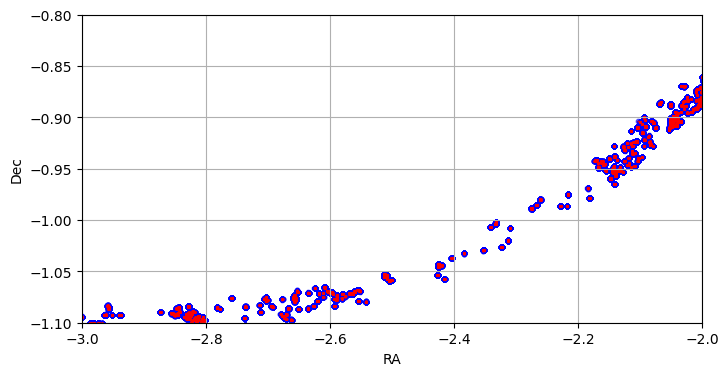

In [101]:
#Plotting ALL

cat_spitzer = SkyCoord(ra=catalogue['ra'][catalogue['spitzer_data']],dec=catalogue['dec'][catalogue['spitzer_data']],frame='icrs')

spitzer_ra_rad = cat_spitzer.ra.wrap_at(180*u.deg).radian
spitzer_dec_rad = cat_spitzer.dec.radian

cat_alma = SkyCoord(ra=catalogue['RA'][catalogue['ALMA_DATA']]*u.deg,dec=catalogue['DEC'][catalogue['ALMA_DATA']]*u.deg,frame='icrs')

alma_ra_rad = cat_spitzer.ra.wrap_at(180*u.deg).radian
alma_dec_rad = cat_spitzer.dec.radian


fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot()

ax.scatter(spitzer_ra_rad, spitzer_dec_rad, marker="o", color="blue", alpha=0.6,s=10)
ax.scatter(alma_ra_rad, alma_dec_rad, marker="o", color="red", alpha=0.6,s=0.4)
ax.grid(True)
ax.set_xlabel("RA")
ax.set_ylabel("Dec")
ax.can_zoom()
ax.set_xlim([-3,-2])
ax.set_ylim([-1.1,-0.8])

In [85]:
catalogue['ra'][catalogue['spitzer_data']]

277.801831
277.80699
277.793401
277.796366
277.802062
277.798196
277.805847
277.80004
277.802936
277.803786
277.804738


In [158]:
spicy_names = ['SPICY','RAdeg','DEdeg','GLON','GLAT','p1','p2','p3','class','Si','PAH','alpha','alpha8','alpha24','alphaw4','Env','Group','var','o_ZTFrmag','ZTFrmag','e_ZTFrmag','skew','Spitzer','3.6mag','e_3.6mag','4.5mag','e_4.5mag','5.8mag','e_5.8mag','8.0mag','e_8.0mag','csf','o_3.6mag','o_4.5mag','o_5.8mag','o_8.0mag','2MASS','UKIDSS','VIRAC','GaiaDR2','MIPS','WISEA','ZTFDR3']

spicy_data = Table.read('../JAE/SPICY/table1.dat',format='ascii',names=spicy_names)

spicy_data['spicy_data'] = True

spicy_names.insert(0,'spicy_data')

spicy_data = spicy_data[spicy_names]

In [159]:
spicy_data.write('../JAE/SPICY/table1.ecsv',format='ascii.ecsv',overwrite=True)


In [170]:
spicy_match = join(catalogue,
                   spicy_data,
                   keys_left='designation',
                   keys_right='Spitzer',
                   join_type='inner')

spicy_match['Spitzer_match'] = False

spicy_match['Spitzer_match'][spicy_match['designation'] == spicy_match['Spitzer']] = True



In [175]:
spicy_match.write('../JAE/SPICY/spicy_match.ecsv',format='ascii.ecsv',overwrite=True)

Text(0.5, 1.0, 'Spicy and ALMAGAL survey\n2224 sources')

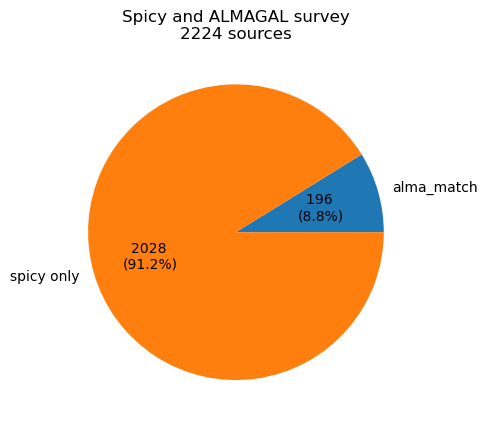

In [171]:
# Circular plot

labels = ['alma_match','spicy only']
data = [len(spicy_match[(spicy_match['match'] == True) & (spicy_match['spicy_data'] == True)]),
         len(spicy_match[(spicy_match['match'] == False) & (spicy_match['spicy_data'] == True)])]

fig, ax = plt.subplots()
ax.pie(data,
             labels=labels,
             autopct=lambda pct: f'{pct * sum(data) / 100:.0f} \n({pct:.1f}%)')
ax.set_title(f'Spicy and ALMAGAL survey\n{len(spicy_match)} sources')

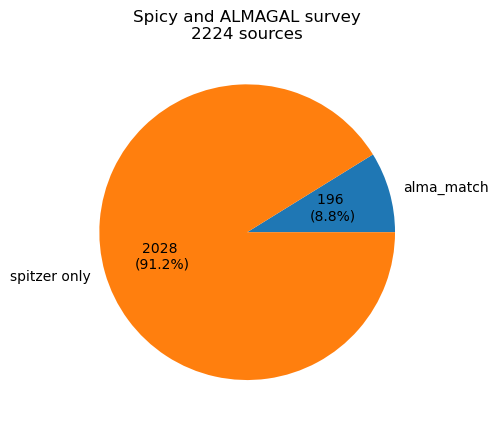

In [190]:
# Circular plot

labels = ['alma_match','spitzer only']
data = [len(spicy_match[(spicy_match['match'] == True)]),
         len(spicy_match[(spicy_match['match'] == False)])]

fig, ax = plt.subplots()
ax.pie(data,
             labels=labels,
             autopct=lambda pct: f'{pct * sum(data) / 100:.0f} \n({pct:.1f}%)')
ax.set_title(f'Spicy and ALMAGAL survey\n{len(spicy_match)} sources')
plt.savefig('../JAE/SPICY/spicy_alma.jpg',format='jpg')

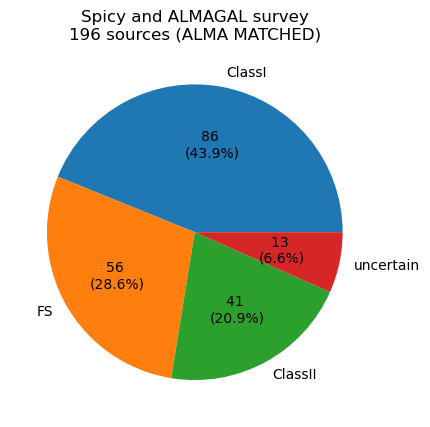

In [189]:
# Circular plot  #2

labels = ['ClassI','FS','ClassII','ClassIII','uncertain']
spicy_match_alma_class = list(spicy_match[spicy_match['match'] == True]['class'])
data = [
    spicy_match_alma_class.count(label)
    for label in labels
]


labels, data = zip(*[(label, count) for label, count in zip(labels, data) if count > 0])

labels = list(labels)
data = list(data)

fig, ax = plt.subplots()
ax.pie(data,
             labels=labels,
             autopct=lambda pct: f'{pct * sum(data) / 100:.0f} \n({pct:.1f}%)')
ax.set_title(f'Spicy and ALMAGAL survey\n{len(spicy_match_alma_class)} sources (ALMA MATCHED)')
plt.savefig('../JAE/SPICY/spicy_alma_match.jpg',format='jpg')